In [2]:
%load_ext rpy2.ipython

/Users/arturohernanzcarrasco-munoz/code/analisis_datos_series_temporales/.venv/lib/python3.9/site-packages/rpy2/ipython/rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [3]:
%%R
lib_loc <- "lib_loc"

In [4]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [5]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))



if (!require("psych")) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr")) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc")) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("GGally")) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot")) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)
if (!require("survey", lib.loc = lib_loc)) install.packages("survey", lib = lib_loc)
library(survey, lib.loc = lib_loc)
if (!require("mitools", lib.loc = lib_loc)) install.packages("mitools", lib = lib_loc)
library(mitools, lib.loc = lib_loc)
if (!require("relaimpo", lib.loc = lib_loc)) install.packages("relaimpo", lib = lib_loc)
library(relaimpo, lib.loc = lib_loc)
if (!require("FSelectorRcpp", lib.loc = lib_loc)) install.packages("FSelectorRcpp", lib = lib_loc)
library(FSelectorRcpp, lib.loc = lib_loc)
if (!require("ranger", lib.loc = lib_loc)) install.packages("ranger", lib = lib_loc)
library(ranger, lib.loc = lib_loc)
if (!require("Boruta", lib.loc = lib_loc)) install.packages("Boruta", lib = lib_loc)
library(Boruta, lib.loc = lib_loc)
if (!require("randomForest", lib.loc = lib_loc)) install.packages("randomForest", lib = lib_loc)
library(randomForest, lib.loc = lib_loc)

if (!require("ggsci", lib.loc = lib_loc)) install.packages("ggsci", lib = lib_loc)
library(ggsci, lib.loc = lib_loc)
if (!require("dendextend", lib.loc = lib_loc)) install.packages("dendextend", lib = lib_loc)
library(dendextend, lib.loc = lib_loc)
if (!require("factoextra", lib.loc = lib_loc)) install.packages("factoextra", lib = lib_loc)
library(factoextra, lib.loc = lib_loc)
if (!require("FactoMineR", lib.loc = lib_loc)) install.packages("FactoMineR", lib = lib_loc)
library(FactoMineR, lib.loc = lib_loc)
if (!require("nFactors", lib.loc = lib_loc)) install.packages("nFactors", lib = lib_loc)
library(nFactors, lib.loc = lib_loc)


if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}



The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages are in
	/var/folders/1d/8y2whlcd4cx508sll_rm0nwh0000gn/T//RtmpGttw8V/downloaded_packages

The downloaded binary packages 

Loading required package: psych
also installing the dependencies ‘mnormt’, ‘GPArotation’

trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/mnormt_2.1.1.tgz'
trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/GPArotation_2025.3-1.tgz'
trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/psych_2.5.6.tgz'
Loading required package: plyr
trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/plyr_1.8.9.tgz'
Content type 'application/x-gzip' length 984753 bytes (961 KB)
downloaded 961 KB

Loading required package: Rmisc
trying URL 'https://cloud.r-project.org/bin/macosx/big-sur-arm64/contrib/4.5/Rmisc_1.5.1.tgz'
Content type 'application/x-gzip' length 51868 bytes (50 KB)
downloaded 50 KB

Loading required package: lattice
Loading required package: GGally
Loading required package: ggplot2

Attaching package: ‘ggplot2’

The following objects are masked from ‘package:psych’:

    %+%, alpha

Loa

# Carga del fichero

In [9]:
%%R

dfMedidas <- read.csv("accelerometer_gyro_mobile_phone_dataset.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [10]:
%%R
head(dfMedidas, 5)

       accX     accY     accZ     gyroX     gyroY     gyroZ timestamp Activity
1 -0.496517 3.785628 8.954828 -0.142849 -0.126159 -0.022539   34:22.9        1
2 -0.462388 3.869603 9.281898  0.084349  0.096695  0.092130   34:23.0        1
3 -0.296084 3.820505 8.930728  0.061763  0.051543  0.071287   34:23.1        1
4 -0.469723 3.890110 8.744067  0.007641  0.028679  0.109433   34:23.2        1
5 -0.472418 4.109105 8.941207 -0.123640  0.099057  0.051943   34:23.3        1


Analizamos los tipos de variables

In [11]:
%%R
str(dfMedidas)

'data.frame':	31991 obs. of  8 variables:
 $ accX     : num  -0.497 -0.462 -0.296 -0.47 -0.472 ...
 $ accY     : num  3.79 3.87 3.82 3.89 4.11 ...
 $ accZ     : num  8.95 9.28 8.93 8.74 8.94 ...
 $ gyroX    : num  -0.14285 0.08435 0.06176 0.00764 -0.12364 ...
 $ gyroY    : num  -0.1262 0.0967 0.0515 0.0287 0.0991 ...
 $ gyroZ    : num  -0.0225 0.0921 0.0713 0.1094 0.0519 ...
 $ timestamp: Factor w/ 21776 levels "00:00.0","00:00.1",..: 11041 11042 11043 11044 11045 11046 11047 11048 11049 11050 ...
 $ Activity : int  1 1 1 1 1 1 1 1 1 1 ...


# EDA

Como podemos observar hay un total de 31991 instancias con 8 variables.
Estas variables se pueden dividir en categóricas y numéricas:

1)   Categóricas:
  * timestamp: Fecha

2)   Numéricas:
  * accX: Componente X del vector del acelerómetro
  * accY: Componente Y del vector del acelerómetro
  * accZ: Componente Z del vector del acelerómetro
  * gyroX: Componente X del vector del giroscópio
  * gyroY: Componente Y del vector del giroscópio
  * gyroX: Componente Z del vector del giroscópio
  * Activity (Variable objetivo): Actividad detectada (de pie, andando) 

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [12]:
%%R
describe(dfMedidas)

           vars     n     mean      sd   median  trimmed     mad   min      max
accX          1 31991     0.02    0.74    -0.02     0.00    0.70 -3.67     4.68
accY          2 31991     2.15    1.09     2.12     2.16    1.12 -4.39     6.38
accZ          3 31991     9.54    2.06     9.41     9.46    2.49  4.30    17.59
gyroX         4 31991     0.00    0.31     0.02     0.01    0.24 -1.47     1.33
gyroY         5 31991    -0.01    0.25    -0.01    -0.02    0.21 -1.43     1.48
gyroZ         6 31991    -0.01    0.27     0.01     0.00    0.23 -1.89     1.48
timestamp*    7 31991 10774.60 6617.44 10681.00 10745.85 9012.73  1.00 21776.00
Activity      8 31991     0.98    0.13     1.00     1.00    0.00  0.00     1.00
              range  skew kurtosis    se
accX           8.35  0.32     0.65  0.00
accY          10.76 -0.04    -0.06  0.01
accZ          13.30  0.28    -0.80  0.01
gyroX          2.80 -0.58     1.67  0.00
gyroY          2.91  0.09     1.13  0.00
gyroZ          3.38 -0.43     2.55

Como podemos ver que no hay valores faltantes ni constantes, la cardinalidad máxima dentro de las variables categóricas es el número de instancias, sin embargo, ese atributo indica la fecha, por lo que lo trataremos como una serie temporal.

In [18]:
%%R

dfMedidas <- read.csv("accelerometer_gyro_mobile_phone_dataset.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


In [19]:
%%R
describe(dfMedidas)

           vars     n     mean      sd   median  trimmed     mad   min      max
accX          1 31991     0.02    0.74    -0.02     0.00    0.70 -3.67     4.68
accY          2 31991     2.15    1.09     2.12     2.16    1.12 -4.39     6.38
accZ          3 31991     9.54    2.06     9.41     9.46    2.49  4.30    17.59
gyroX         4 31991     0.00    0.31     0.02     0.01    0.24 -1.47     1.33
gyroY         5 31991    -0.01    0.25    -0.01    -0.02    0.21 -1.43     1.48
gyroZ         6 31991    -0.01    0.27     0.01     0.00    0.23 -1.89     1.48
timestamp*    7 31991 10774.60 6617.44 10681.00 10745.85 9012.73  1.00 21776.00
Activity      8 31991     0.98    0.13     1.00     1.00    0.00  0.00     1.00
              range  skew kurtosis    se
accX           8.35  0.32     0.65  0.00
accY          10.76 -0.04    -0.06  0.01
accZ          13.30  0.28    -0.80  0.01
gyroX          2.80 -0.58     1.67  0.00
gyroY          2.91  0.09     1.13  0.00
gyroZ          3.38 -0.43     2.55

In [20]:
%%R
str(dfMedidas)

'data.frame':	31991 obs. of  8 variables:
 $ accX     : num  -0.497 -0.462 -0.296 -0.47 -0.472 ...
 $ accY     : num  3.79 3.87 3.82 3.89 4.11 ...
 $ accZ     : num  8.95 9.28 8.93 8.74 8.94 ...
 $ gyroX    : num  -0.14285 0.08435 0.06176 0.00764 -0.12364 ...
 $ gyroY    : num  -0.1262 0.0967 0.0515 0.0287 0.0991 ...
 $ gyroZ    : num  -0.0225 0.0921 0.0713 0.1094 0.0519 ...
 $ timestamp: Factor w/ 21776 levels "00:00.0","00:00.1",..: 11041 11042 11043 11044 11045 11046 11047 11048 11049 11050 ...
 $ Activity : int  1 1 1 1 1 1 1 1 1 1 ...


Analizamos cada variable con histogramas:

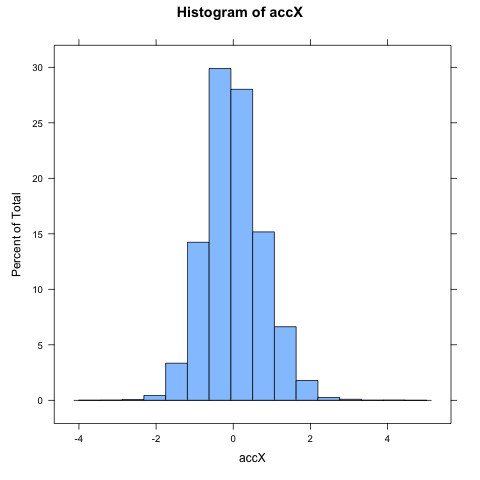

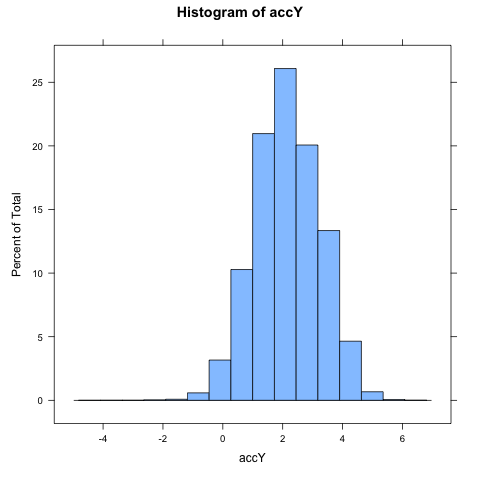

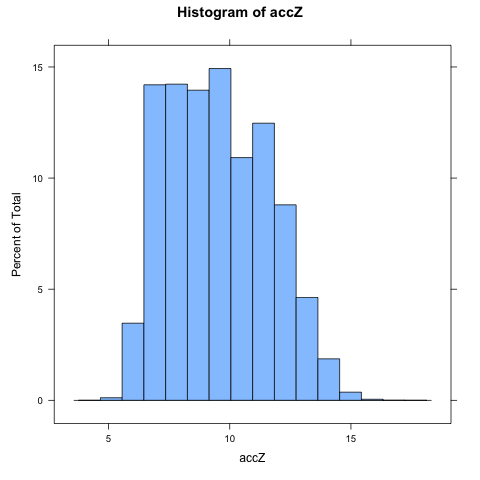

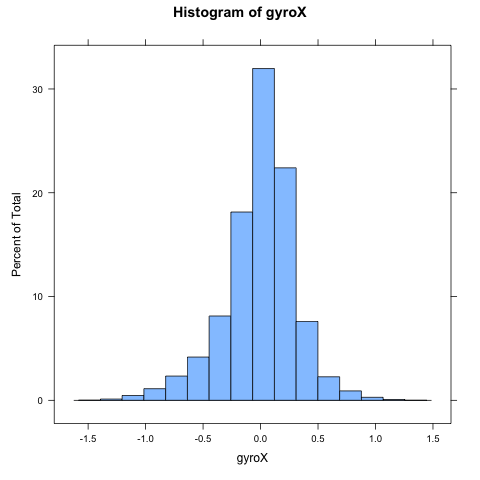

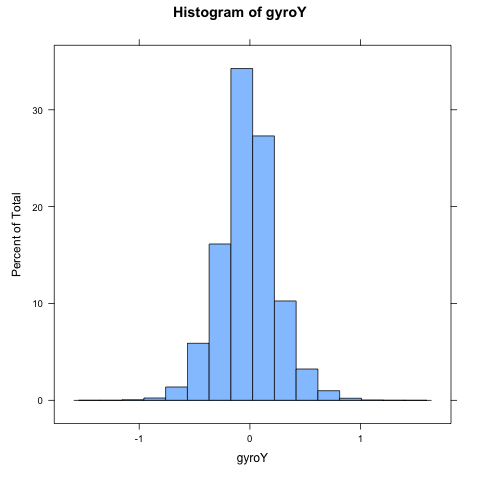

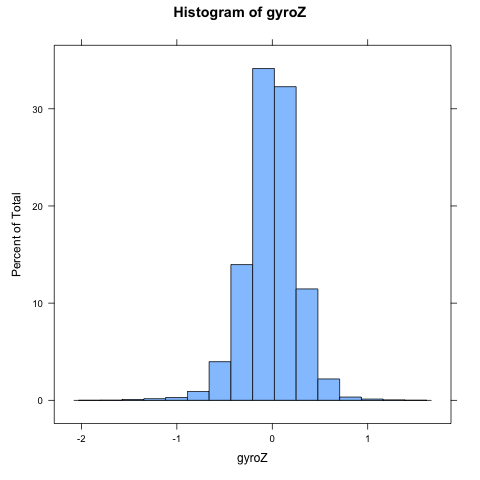

In [22]:
%%R 
print(histogram(dfMedidas$accX, main = "Histogram of accX", xlab = "accX"))
print(histogram(dfMedidas$accY, main = "Histogram of accY", xlab = "accY"))
print(histogram(dfMedidas$accZ, main = "Histogram of accZ", xlab = "accZ"))
print(histogram(dfMedidas$gyroX, main = "Histogram of gyroX", xlab = "gyroX"))
print(histogram(dfMedidas$gyroY, main = "Histogram of gyroY", xlab = "gyroY"))
print(histogram(dfMedidas$gyroZ, main = "Histogram of gyroZ", xlab = "gyroZ"))


Podemos ver que las variables siguen una distribución normal, sin embargo, el componente Z del vector del acelerómetro presenta una leve asimetría a la derecha.

Evaluamos también la presencia de outliers con los diagramas de caja.

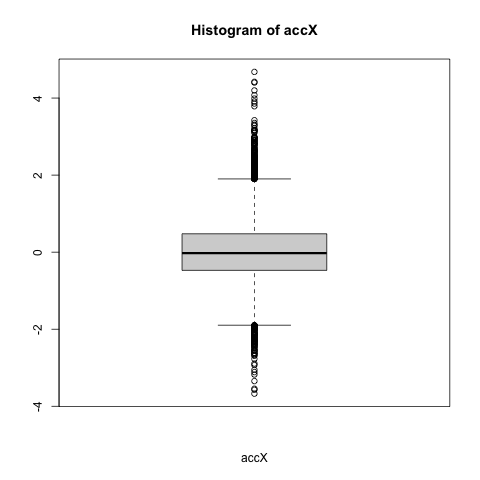

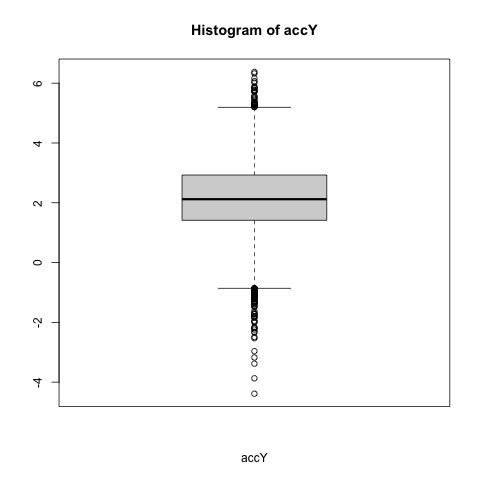

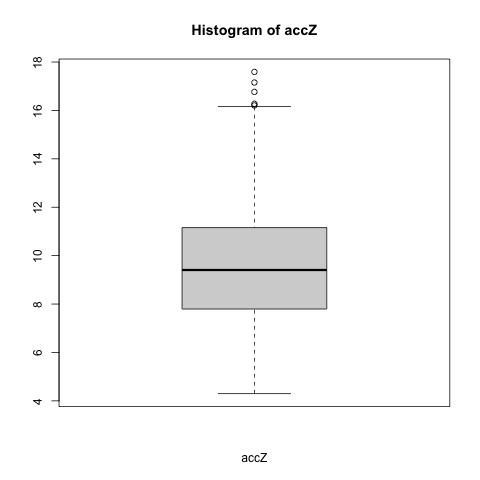

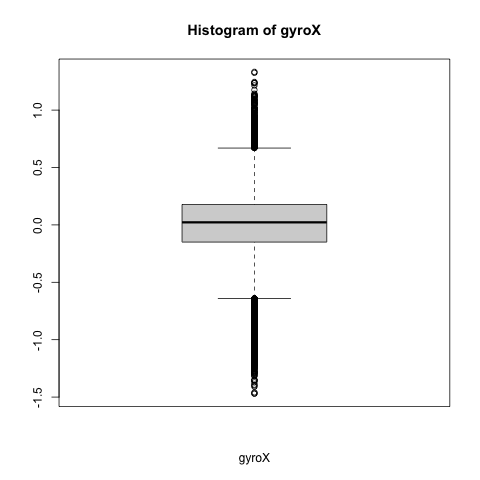

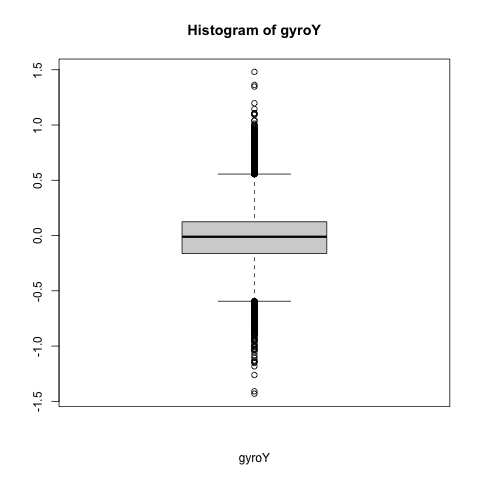

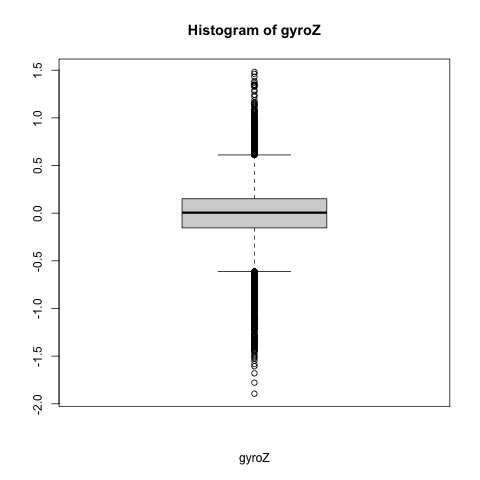

In [23]:
%%R 
boxplot(dfMedidas$accX, main = "Histogram of accX", xlab = "accX")
boxplot(dfMedidas$accY, main = "Histogram of accY", xlab = "accY")
boxplot(dfMedidas$accZ, main = "Histogram of accZ", xlab = "accZ")
boxplot(dfMedidas$gyroX, main = "Histogram of gyroX", xlab = "gyroX")
boxplot(dfMedidas$gyroY, main = "Histogram of gyroY", xlab = "gyroY")
boxplot(dfMedidas$gyroZ, main = "Histogram of gyroZ", xlab = "gyroZ")


Podemos ver que todas las variables a excepción del componente Z del vector del acelerómetro presentan una gran cantidad de outliers

De estas gráficas podemos sacar las siguientes conclusiones:

* Los valores más altos de lluvia se dan en verano y en primavera, dos de las estaciones con mayor uso de las bicicletas, por lo que la presencia de outliers de lluvia es estadísticamente normal.
* Los valores más altos de nieve se dan en otoño y invierno, y aunque en invierno no se usan mucho las bicicletas, en otoño sí, por lo que se da el mismo caso que con la lluvia.
* Los valores más altos de viento se dan en primavera y verano, dándose la misma situación que en los dos casos anteriores.
* Los valores más altos de radiación solar se dan también en primavera y verano, dándose la misma situación que en los dos casos anteriores.

Por todo esto, se puede ver que estos valores que en un principio pueden parecer atípicos, muestran la correlación entre las estaciones y las condiciones meteorológicas.

Haciendo uso de la distancia Cook, veremos si estos outliers son puntos de apalancamiento (tienen mucha influencia)

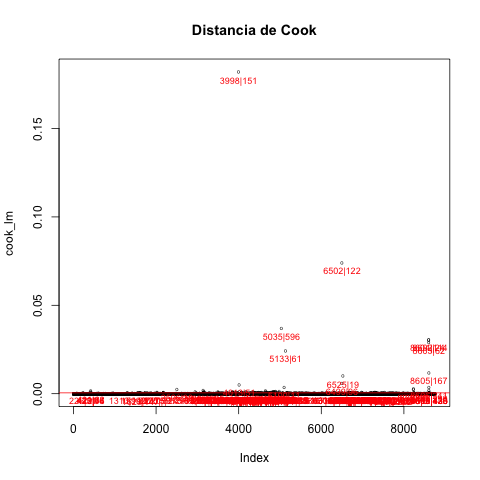

In [15]:
%%R

fit_lm <- lm(Rented_Bike_Count ~ Rainfall + Snowfall + Wind_speed + Solar_Radiation, data = dfMedidas)
cook_lm <- cooks.distance(fit_lm)

plot(cook_lm, pch = "o", cex = 0.5, main = "Distancia de Cook")
abline(h = 4*mean(cook_lm), col = "red")  # línea de corte
text(x = 1 : length(cook_lm) + 1, y = cook_lm - 0.005, cex = 0.75,
     labels = ifelse(cook_lm > 4 * mean(cook_lm), paste0(names(cook_lm),"|",round(dfMedidas$Rented_Bike_Count[as.numeric(names(cook_lm))],0)), ""), col="red")


In [16]:
%%R
influentes <- which(cook_lm > 4*mean(cook_lm))

dfMedidas[order(cook_lm, decreasing = TRUE)[1:10], c("Rented_Bike_Count", "Rainfall", "Snowfall", "Wind_speed", "Solar_Radiation")]

     Rented_Bike_Count Rainfall Snowfall Wind_speed Solar_Radiation
3998               151     35.0      0.0        2.4            0.06
6502               122     29.5      0.0        2.1            0.00
5035               596     21.5      0.0        0.7            0.14
8602                24      9.1      7.1        3.0            0.00
8604               114      0.0      8.8        2.3            0.07
8603                62      0.0      8.8        1.8            0.00
5133                61     24.0      0.0        0.1            0.04
8605               167      1.8      7.0        1.9            0.40
6525                19     21.0      0.0        0.6            0.00
6499                96     18.5      0.0        0.8            0.01


Estos son los valores que más influyen, como podemos ver se tratan de outliers de la variable rainfall y snowfall.

Con esto podemos ver que estos outliers son importantes, más adelante decidiremos si se eliminan o no.

## Análisis de Correlación:

### Correlación entre variables numéricas

In [31]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
num_vars <- num_vars[, !names(num_vars) %in% c("Activity")]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


       accX  accY  accZ gyroX gyroY gyroZ
accX   1.00 -0.19  0.02 -0.03 -0.03 -0.05
accY  -0.19  1.00 -0.08  0.00 -0.01  0.00
accZ   0.02 -0.08  1.00 -0.03 -0.02  0.01
gyroX -0.03  0.00 -0.03  1.00  0.13  0.15
gyroY -0.03 -0.01 -0.02  0.13  1.00  0.05
gyroZ -0.05  0.00  0.01  0.15  0.05  1.00


Y de una forma más visual:

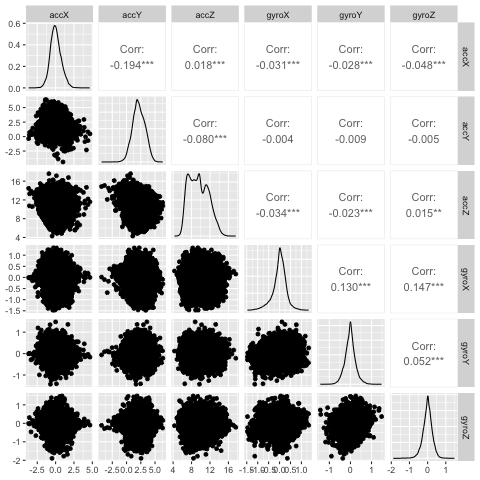

In [32]:
%%R
ggpairs(num_vars, size = 3)

In addition: Warning messages:
1: In text.default(pos.xlabel[, 1], pos.xlabel[, 2], newcolnames, srt = tl.srt,  :
  "size" is not a graphical parameter
2: In text.default(pos.ylabel[, 1], pos.ylabel[, 2], newrownames, col = tl.col,  :
  "size" is not a graphical parameter
3: In title(title, ...) : "size" is not a graphical parameter


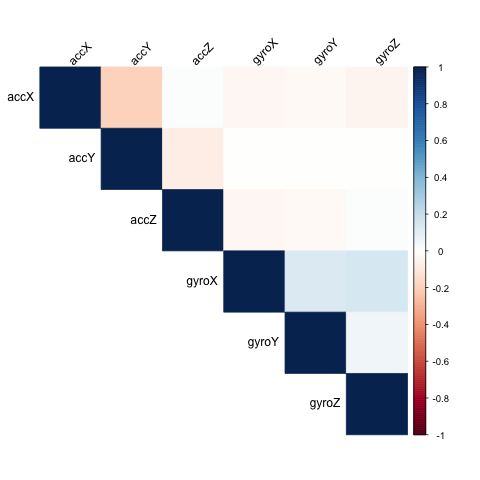

In [33]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45,
        size = 10)

Como podemos ver, no hay una correlación relevante entre las variables, la mayor es del 19.4%, por lo que no podemos sacar unas conclusiones relevantes.

### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [34]:
%%R
library(ggplot2)

target <- "Activity"

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)


      Variable  Correlation
accX      accX  0.126771407
accY      accY  0.113485743
accZ      accZ -0.014447917
gyroZ    gyroZ -0.009459611
gyroY    gyroY -0.001606282
gyroX    gyroX  0.001469394


Como podemos ver la variable más relacionada con la objetivo es el componente X del vector del acelerómetro (12.6% de correlación).

## Selección de Atributos:

Analizaremos la importancia de los atributos mediante ranking y embedido, para, de esta forma, poder evaluar la posibilidad de eliminar algún atributo más.

### Selección por Ranking

Utilizamos Boruta como métrica de importancia de atributos

Boruta performed 10 iterations in 1.354731 mins.
 6 attributes confirmed important: accX, accY, accZ, gyroX, gyroY and 1
more;
 No attributes deemed unimportant.
        meanImp medianImp    minImp    maxImp normHits  decision
gyroZ  5.715324  5.811910  3.852955  7.714441        1 Confirmed
gyroY  3.958787  4.251020  2.051899  5.117495        1 Confirmed
gyroX  7.538629  7.538878  5.449301  9.025576        1 Confirmed
accZ  21.621077 21.324662 17.471567 24.463030        1 Confirmed
accY  39.150985 38.564798 36.527651 42.751296        1 Confirmed
accX  40.676977 40.230772 39.320691 42.696687        1 Confirmed


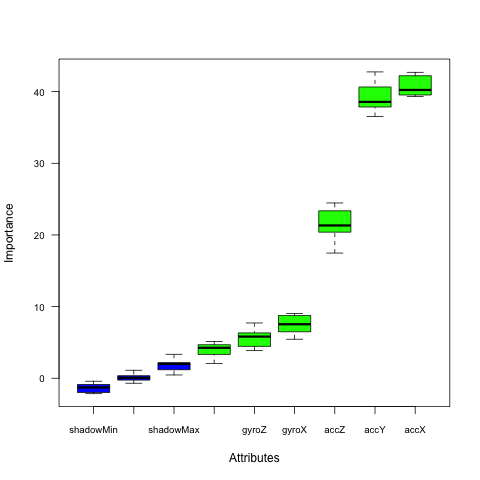

In [35]:
%%R
formula <- to_formula( c("accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"), "Activity")

out.boruta <- Boruta(formula, data = dfMedidas)
plot(out.boruta, cex.axis = 0.8, las=1)
print(out.boruta)
attStats(out.boruta)

Podemos ver que el atributo más importante es accX seguido de accY, el resto están muy alejados de estos valores, sin embargo, el algoritmo los marca todos como importantes.

### Seleccion por Embedido

Como criterio de embedido usaremos random forest, serán más importantes aquellos atributos usados en los árboles con menor error

In [36]:
%%R
modelo.rf <- randomForest(formula, data = dfMedidas, ntree=1000,
                          keep.forest=FALSE, importance=TRUE, na.action = na.roughfix)

rf_imp <- importance(modelo.rf, importance.type = 1)
print(rf_imp)

       %IncMSE IncNodePurity
accX  74.70838     110.66869
accY  73.10985     105.10391
accZ  48.76114      96.95587
gyroX 19.72356      69.51574
gyroY 13.87888      65.39335
gyroZ 16.69880      64.57054


In addition: Warning message:
In randomForest.default(m, y, ...) :
  The response has five or fewer unique values.  Are you sure you want to do regression?


De nuevo, podemos ver que las variables más importantes son accX y accY, además, podemos ver que las variables con un valor cercano o menor que 18, como giroX o giroY, son muy poco relevantes. Sin embargo, no podemos eliminar ninguna variable.

## Reducción de Dimensionalidad:

Aunque ya hemos realizado un estudio sobre la correlación de los atributos, ahora analizaremos más detalladamente si se puede o no considerar reducir la dimensionalidad del problema fusionando algunos más.

In [37]:
%%R
atributos <- c("accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ")

res.pca <- prcomp(dfMedidas[,atributos], scale = TRUE) 
summary(res.pca)

Importance of components:
                          PC1    PC2    PC3    PC4    PC5    PC6
Standard deviation     1.1246 1.0873 1.0026 0.9670 0.9078 0.8881
Proportion of Variance 0.2108 0.1970 0.1675 0.1559 0.1373 0.1315
Cumulative Proportion  0.2108 0.4078 0.5754 0.7312 0.8686 1.0000


Como podemos ver, a partir de 5 PCAs la varianza explicada es buena (>80%), sin embargo, se puede considerar que el mejor resultado es de 6 (~90%), ya que reduce la dimensionalidad sin perder apenas explicación.

In [33]:
%%R
head(dfMedidas)

  Rented_Bike_Count Seasons

    Holiday Functioning Day        PC1       PC2
1               254  Winter No Holiday             Yes -0.7332683 -2.062389
2               204  Winter No Holiday             Yes -0.2015324 -2.175319
3               173  Winter No Holiday             Yes -0.2945258 -2.127447
4               107  Winter No Holiday             Yes -0.2678435 -2.096548
5                78  Winter No Holiday             Yes -0.9726329 -1.968856
6               100  Winter No Holiday             Yes -0.6756575 -2.024013
        PC3       PC4       PC5         PC6
1 0.7788506 0.6870143 1.2434042 -0.45228103
2 1.2975470 0.6928921 1.0023137  0.14121549
3 1.1443520 0.7290576 0.9126162  0.07273008
4 1.1204707 0.7546967 0.7927381  0.13402031
5 0.4837322 0.8300959 0.8496979 -0.41897023
6 0.7498297 0.8482615 0.6657240 -0.07480163


Ahora, hemos eliminado los atributos anteriores y los hemos sustituido por las PCAs seleccionadas previamente, reduciendo la dimensionalidad del problema.

Dado que se trata de un problema de regresión, no se puede aplicar LDA, pues su objetivo es separar las clases.